# Adaptive Image Feature Extraction and Classification System

This project implements an end-to-end computer vision pipeline that processes images, dynamically extracts multi-modal features (statistical, pixel-level, and texture-based), trains machine learning classifiers, and performs rigorous evaluation.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from skimage.feature import graycomatrix, graycoprops
import cv2
import warnings
warnings.filterwarnings('ignore')

## 1. Dataset Loading and Preprocessing
We will use the Fashion-MNIST dataset, which offers richer structural and statistical patterns than classic MNIST.

In [2]:
print("Loading Fashion-MNIST dataset...")
# Load a subset for fast, efficient computation within the notebook
X, y = fetch_openml('Fashion-MNIST', version=1, return_X_y=True, as_frame=False)
X = X[:10000] # Use 10,000 samples for swift execution
y = y[:10000].astype(int)

# Reshape to original 28x28 image dimensions
images = X.reshape(-1, 28, 28)
print(f"Loaded {images.shape[0]} images of shape {images.shape[1:]}")

Loading Fashion-MNIST dataset...
Loaded 10000 images of shape (28, 28)


### Visualize Sample Images from the Dataset

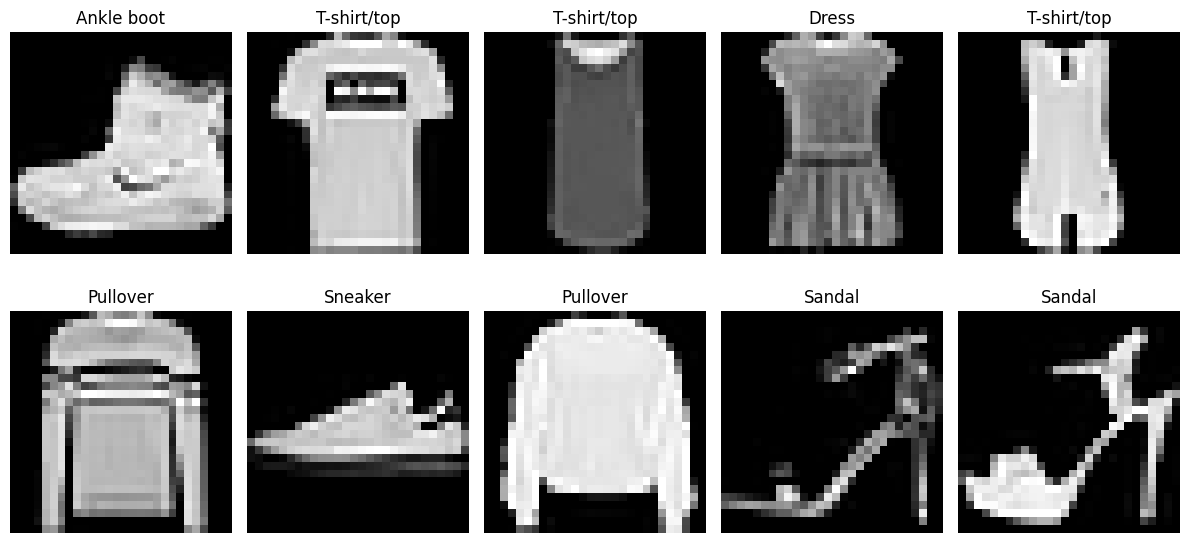

In [3]:
class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

fig, axes = plt.subplots(2, 5, figsize=(12, 6))
for i, ax in enumerate(axes.flat):
    ax.imshow(images[i], cmap='gray')
    ax.set_title(class_names[y[i]])
    ax.axis('off')
plt.tight_layout()
plt.show()

## 2. Adaptive Feature Extraction
We will extract three layers of features from each image:
1. **Pixel-level features**: Downsampled flattened raw pixel values.
2. **Statistical features**: Mean, standard deviation, skewness, and kurtosis of the pixel intensities.
3. **Texture (Statistical) features**: Gray-Level Co-occurrence Matrix (GLCM) properties (Contrast, Correlation, Energy, Homogeneity).

In [4]:
def extract_features(imgs):
    feature_list = []
    for img in imgs:
        # Ensure image is in float32 for OpenCV operations and uint8 for GLCM
        img_f32 = img.astype(np.float32)
        img_uint8 = img.astype(np.uint8)

        # 1. Pixel-level features (downsample to 14x14 to avoid overfitting and high dimensionality)
        pixel_features = cv2.resize(img_f32, (14, 14)).flatten()

        # 2. Basic Statistical features
        mean_val = np.mean(img_f32)
        std_val = np.std(img_f32)
        median_val = np.median(img_f32)

        # 3. Texture-level features (GLCM properties)
        glcm = graycomatrix(img_uint8, distances=[1], angles=[0], levels=256, symmetric=True, normed=True)
        contrast = graycoprops(glcm, 'contrast')[0, 0]
        correlation = graycoprops(glcm, 'correlation')[0, 0]
        energy = graycoprops(glcm, 'energy')[0, 0]
        homogeneity = graycoprops(glcm, 'homogeneity')[0, 0]

        # Combine all features into one 1D array
        combined_features = np.hstack([
            pixel_features,
            [mean_val, std_val, median_val, contrast, correlation, energy, homogeneity]
        ])
        feature_list.append(combined_features)

    return np.array(feature_list)

print("Extracting adaptive features from all images...")
X_features = extract_features(images)
print(f"New Feature Vector Shape: {X_features.shape}")

Extracting adaptive features from all images...
New Feature Vector Shape: (10000, 203)


## 3. Train-Test Split & Normalization

In [5]:
X_train, X_test, y_train, y_test = train_test_split(X_features, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print("Features scaled and ready for model training.")

Features scaled and ready for model training.


## 4. Classifier Evaluation
We evaluate and compare a **Random Forest Classifier** and a **Support Vector Machine (SVM)** on our hybrid feature space.

In [6]:
# Train Random Forest Classifier
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train_scaled, y_train)
y_pred_rf = rf_model.predict(X_test_scaled)

# Train Support Vector Machine Classifier
svm_model = SVC(kernel='rbf', C=5, random_state=42)
svm_model.fit(X_train_scaled, y_train)
y_pred_svm = svm_model.predict(X_test_scaled)

print(f"Random Forest Accuracy: {accuracy_score(y_test, y_pred_rf):.4f}")
print(f"SVM Accuracy: {accuracy_score(y_test, y_pred_svm):.4f}")

Random Forest Accuracy: 0.8460
SVM Accuracy: 0.8720


### Performance Metrics & Confusion Matrix Visualizations

In [7]:
print("=== Random Forest Classification Report ===")
print(classification_report(y_test, y_pred_rf, target_names=class_names))

print("\n=== SVM Classification Report ===")
print(classification_report(y_test, y_pred_svm, target_names=class_names))

=== Random Forest Classification Report ===
              precision    recall  f1-score   support

 T-shirt/top       0.80      0.84      0.82       189
     Trouser       0.98      0.94      0.96       205
    Pullover       0.77      0.72      0.74       203
       Dress       0.81      0.88      0.84       204
        Coat       0.71      0.76      0.73       195
      Sandal       0.92      0.95      0.94       198
       Shirt       0.69      0.62      0.65       204
     Sneaker       0.91      0.89      0.90       204
         Bag       0.96      0.95      0.96       198
  Ankle boot       0.91      0.91      0.91       200

    accuracy                           0.85      2000
   macro avg       0.85      0.85      0.85      2000
weighted avg       0.85      0.85      0.85      2000


=== SVM Classification Report ===
              precision    recall  f1-score   support

 T-shirt/top       0.80      0.84      0.82       189
     Trouser       0.98      0.97      0.98       205

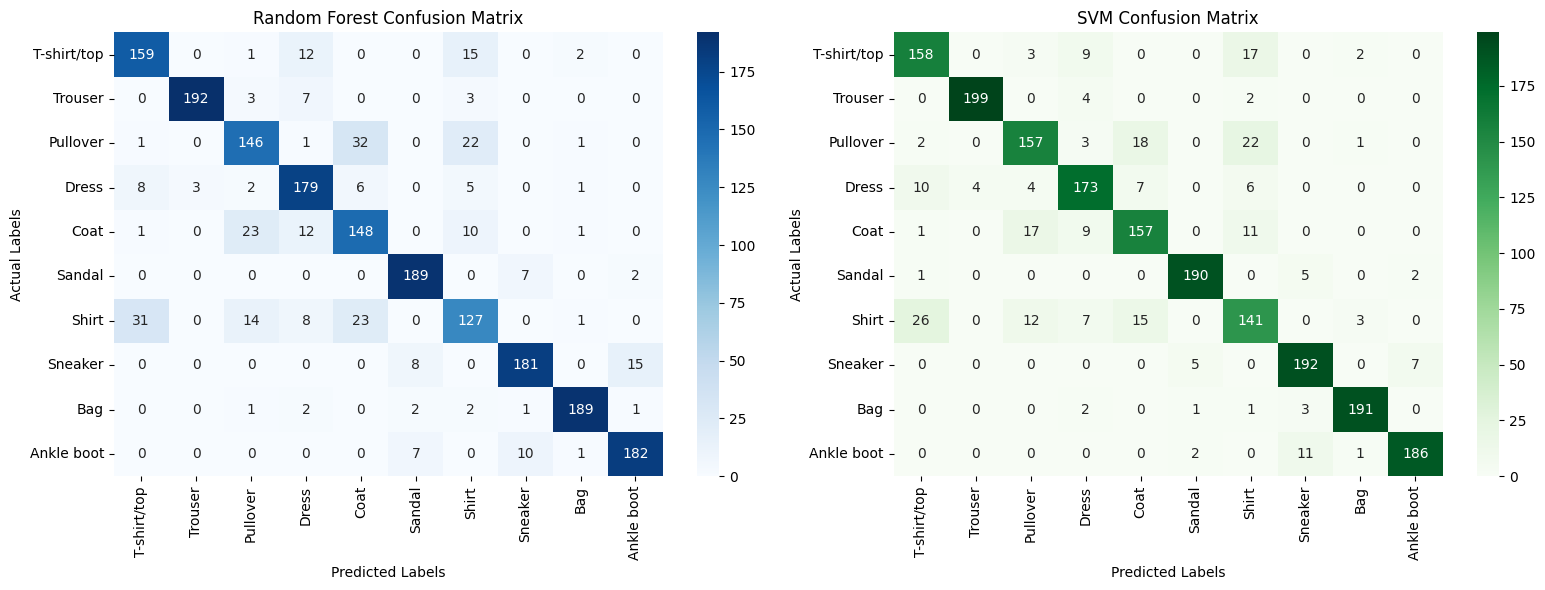

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.heatmap(confusion_matrix(y_test, y_pred_rf), annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names, ax=axes[0])
axes[0].set_title('Random Forest Confusion Matrix')
axes[0].set_ylabel('Actual Labels')
axes[0].set_xlabel('Predicted Labels')

sns.heatmap(confusion_matrix(y_test, y_pred_svm), annot=True, fmt='d', cmap='Greens',
            xticklabels=class_names, yticklabels=class_names, ax=axes[1])
axes[1].set_title('SVM Confusion Matrix')
axes[1].set_ylabel('Actual Labels')
axes[1].set_xlabel('Predicted Labels')

plt.tight_layout()
plt.show()

## 5. Live Prediction on Custom Uploaded Images

Upload your own fashion item photo. It is automatically converted to match Fashion-MNIST (light object on black background, cropped, centered, 28x28) before prediction, so normal product photos with white backgrounds work.

Saving elegant-brown-leather-handbag-classic-tote-bag-with-top-handles-isolated-white-background_1099914-3468.avif to elegant-brown-leather-handbag-classic-tote-bag-with-top-handles-isolated-white-background_1099914-3468.avif
User uploaded file "elegant-brown-leather-handbag-classic-tote-bag-with-top-handles-isolated-white-background_1099914-3468.avif" with length 10628 bytes


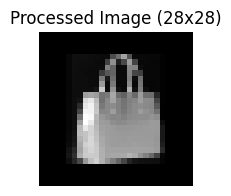

Predictions for elegant-brown-leather-handbag-classic-tote-bag-with-top-handles-isolated-white-background_1099914-3468.avif:
  - Random Forest Predicts: Bag
  - SVM Classifier Predicts: Bag
      RF Bag: 32.0%
      RF T-shirt/top: 18.0%
      RF Shirt: 12.0%


In [9]:
from google.colab import files
import io

def preprocess_like_fashion_mnist(img_gray):
    """Make an arbitrary grayscale photo look like a Fashion-MNIST sample:
    light object, black background, cropped, centered, 28x28."""
    img = img_gray.copy()

    # 1. Fashion-MNIST has a BLACK background. If the border is bright, invert.
    border = np.concatenate([img[0, :], img[-1, :], img[:, 0], img[:, -1]])
    if np.median(border) > 127:
        img = 255 - img

    # 2. Crop tightly around the object (pixels clearly brighter than background)
    bg = np.median(np.concatenate([img[0, :], img[-1, :], img[:, 0], img[:, -1]]))
    mask = img.astype(np.int16) - int(bg) > 30
    ys, xs = np.where(mask)
    if len(ys) > 0:
        img = img[ys.min():ys.max() + 1, xs.min():xs.max() + 1]

    # 3. Pad to a square (black padding), keeping the aspect ratio
    h, w = img.shape
    side = max(h, w)
    canvas = np.zeros((side, side), dtype=np.uint8)
    canvas[(side - h) // 2:(side - h) // 2 + h, (side - w) // 2:(side - w) // 2 + w] = img

    # 4. Resize object to 20x20 and center it in a 28x28 frame (MNIST-style margin)
    obj = cv2.resize(canvas, (20, 20), interpolation=cv2.INTER_AREA)
    out = np.zeros((28, 28), dtype=np.uint8)
    out[4:24, 4:24] = obj

    # 5. Stretch contrast to the full 0-255 range like the training images
    out = cv2.normalize(out, None, 0, 255, cv2.NORM_MINMAX)
    return out

uploaded = files.upload()

for fn in uploaded.keys():
    print(f'User uploaded file "{fn}" with length {len(uploaded[fn])} bytes')

    file_bytes = np.frombuffer(uploaded[fn], dtype=np.uint8)
    img_raw = cv2.imdecode(file_bytes, cv2.IMREAD_GRAYSCALE)

    if img_raw is None:
        # Fallback for formats OpenCV can't decode (e.g. some AVIF builds)
        try:
            from PIL import Image
            img_raw = np.array(Image.open(io.BytesIO(uploaded[fn])).convert('L'))
        except Exception:
            print("Error: Could not decode image. Please upload a valid image file.")
            continue

    img_resized = preprocess_like_fashion_mnist(img_raw)

    plt.figure(figsize=(2, 2))
    plt.imshow(img_resized, cmap='gray')
    plt.title("Processed Image (28x28)")
    plt.axis('off')
    plt.show()

    # Extract features exactly as in training (reuse the same function)
    features = extract_features(img_resized[np.newaxis, ...])

    features_scaled = scaler.transform(features)

    rf_pred = rf_model.predict(features_scaled)[0]
    svm_pred = svm_model.predict(features_scaled)[0]

    print(f"Predictions for {fn}:")
    print(f"  - Random Forest Predicts: {class_names[rf_pred]}")
    print(f"  - SVM Classifier Predicts: {class_names[svm_pred]}")

    # Show top-3 Random Forest probabilities for transparency
    probs = rf_model.predict_proba(features_scaled)[0]
    for idx in np.argsort(probs)[::-1][:3]:
        print(f"      RF {class_names[idx]}: {probs[idx]*100:.1f}%")
